# Week 1 – Module 2: Data Exploration and Data Preprocessing
### Personalized TED Talks Recommendation System Using Machine Learning

---

## Module Overview & Objectives
Module 2 performs exploratory data analysis (EDA) and rigorous preprocessing on the TED Talks datasets:
1. **Load Datasets**: Ingest `ted_main.csv` and `transcripts.csv` using Pandas.
2. **First Five Records**: Inspect initial records across all features.
3. **Dataset Shape**: Validate row and column dimensions.
4. **Column Names & Data Types**: Catalog schema types, memory footprint, and feature semantics.
5. **Missing Value Audit**: Quantify null counts and percentages per column.
6. **Duplicate Identification**: Detect and resolve redundant records and duplicate URLs.
7. **Duration & Views Analysis**: Deep statistical examination of talk length and audience viewership patterns.
8. **Topics & Tags Distribution**: Extract, parse, and analyze the topical taxonomy across 400+ tags.
9. **Transcript Text Cleaning**:
   - Lowercase normalization
   - Punctuation removal
   - Unnecessary whitespace / newline stripping
   - Stopwords removal using NLTK
10. **Missing Data Handling**: Impute missing transcripts using title/description summaries and handle missing speaker occupations.
11. **Categorical Feature Encoding**: Label encoding for speakers/occupations and multi-hot / indicator encoding for top topics.
12. **EDA Visualizations**:
   - Talk length distribution (Histogram + KDE + Boxplot)
   - Top 10 TED Talk tags
   - Missing values audit chart
   - Views distribution (Raw & Log-scaled)
13. **Dataset & Report Exports**: Save `cleaned_ted_talks.csv`, `cleaned_transcripts.csv`, and `reports/eda_report.txt`.

In [1]:
import os
import sys
import re
import ast
import string
from collections import Counter
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 150

# Load NLTK stopwords
import nltk
nltk_search_dirs = [
    os.path.join(os.getcwd(), 'nltk_data'),
    r'e:\infosys\TED TALKS\nltk_data',
    r'E:\nltk_data',
]
for p in nltk_search_dirs:
    if os.path.exists(p) and p not in nltk.data.path:
        nltk.data.path.append(p)

from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(f"[✓] NLTK Stopwords loaded. Count: {len(stop_words)}")
print("[✓] Environment initialized successfully.")

[✓] NLTK Stopwords loaded. Count: 198
[✓] Environment initialized successfully.


## Task 1: Load Datasets
Load `ted_main.csv` and `transcripts.csv` using Pandas.

In [2]:
ted_main_path = r"E:\infosys\TED TALKS\datasets\ted_main.csv"
transcripts_path = r"E:\infosys\TED TALKS\datasets\transcripts.csv"

df_main = pd.read_csv(ted_main_path)
df_trans = pd.read_csv(transcripts_path)

print(f"[✓] Loaded ted_main.csv: {df_main.shape[0]:,} rows, {df_main.shape[1]} columns")
print(f"[✓] Loaded transcripts.csv: {df_trans.shape[0]:,} rows, {df_trans.shape[1]} columns")

[✓] Loaded ted_main.csv: 2,550 rows, 17 columns
[✓] Loaded transcripts.csv: 2,467 rows, 2 columns


## Task 2: Display First Five Records
Inspect the top 5 records of both datasets.

In [3]:
print("--- FIRST 5 RECORDS: ted_main.csv ---")
display(df_main[['title', 'main_speaker', 'duration', 'views', 'tags', 'url']].head())

print("\n--- FIRST 5 RECORDS: transcripts.csv ---")
display(df_trans.head())

--- FIRST 5 RECORDS: ted_main.csv ---
                             title   main_speaker  duration     views                                                                                                                                        tags                                                                             url
0      Do schools kill creativity?   Ken Robinson      1164  47227110                                                        ['children', 'creativity', 'culture', 'dance', 'education', 'parenting', 'teaching']           https://www.ted.com/talks/ken_robinson_says_schools_kill_creativity\n
1      Averting the climate crisis        Al Gore       977   3200520      ['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainability', 'technology']                  https://www.ted.com/talks/al_gore_on_averting_climate_crisis\n
2                 Simplicity sells    David Pogue      1286   1636292                 ['comp

## Task 3: Check Dataset Shape (Rows and Columns)
Display the dimensions of both datasets.

In [4]:
print(f"ted_main.csv dimensions    : {df_main.shape[0]:,} rows × {df_main.shape[1]} columns")
print(f"transcripts.csv dimensions : {df_trans.shape[0]:,} rows × {df_trans.shape[1]} columns")

ted_main.csv dimensions    : 2,550 rows × 17 columns
transcripts.csv dimensions : 2,467 rows × 2 columns


## Task 4: Display Column Names and Data Types
Inspect data types and non-null counts.

In [5]:
print("=== TED MAIN SCHEMA & TYPES ===")
print(df_main.dtypes)

print("\n=== TRANSCRIPTS SCHEMA & TYPES ===")
print(df_trans.dtypes)

=== TED MAIN SCHEMA & TYPES ===
comments               int64
description           object
duration               int64
event                 object
film_date              int64
languages              int64
main_speaker          object
name                  object
num_speaker            int64
published_date         int64
ratings               object
related_talks         object
speaker_occupation    object
tags                  object
title                 object
url                   object
views                  int64

=== TRANSCRIPTS SCHEMA & TYPES ===
transcript    object
url           object


## Task 5: Check Missing Values in Every Column
Identify null counts and null percentages across all attributes.

In [6]:
print("=== MISSING VALUES IN ted_main.csv ===")
nulls_main = df_main.isnull().sum()
nulls_main_pct = (nulls_main / len(df_main)) * 100
missing_main_df = pd.DataFrame({'Missing Count': nulls_main, 'Percentage (%)': nulls_main_pct.round(3)})
print(missing_main_df[missing_main_df['Missing Count'] > 0])
print(f"Total columns with missing values in ted_main: {(nulls_main > 0).sum()} ('speaker_occupation': 6 nulls)")

print("\n=== MISSING VALUES IN transcripts.csv ===")
nulls_trans = df_trans.isnull().sum()
print(nulls_trans)
print(f"Total missing values in transcripts.csv: {nulls_trans.sum()}")

=== MISSING VALUES IN ted_main.csv ===
                    Missing Count  Percentage (%)
speaker_occupation              6           0.235
Total columns with missing values in ted_main: 1 ('speaker_occupation': 6 nulls)

=== MISSING VALUES IN transcripts.csv ===
transcript    0
url           0
Total missing values in transcripts.csv: 0


## Task 6: Identify Duplicate Records
Identify full-row duplicates and key-level duplicates on `url`, then deduplicate.

In [7]:
main_row_dups = df_main.duplicated().sum()
trans_row_dups = df_trans.duplicated().sum()
main_url_dups = df_main['url'].duplicated().sum()
trans_url_dups = df_trans['url'].duplicated().sum()

print(f"Full-row duplicates in ted_main.csv    : {main_row_dups}")
print(f"Full-row duplicates in transcripts.csv : {trans_row_dups}")
print(f"Duplicate URLs in ted_main.csv         : {main_url_dups}")
print(f"Duplicate URLs in transcripts.csv      : {trans_url_dups}")

# Deduplicate transcripts on url
df_trans_dedup = df_trans.drop_duplicates(subset=['url']).copy()
print(f"[✓] Transcripts deduplicated from {len(df_trans)} to {len(df_trans_dedup)} records.")

Full-row duplicates in ted_main.csv    : 0
Full-row duplicates in transcripts.csv : 3
Duplicate URLs in ted_main.csv         : 0
Duplicate URLs in transcripts.csv      : 3
[✓] Transcripts deduplicated from 2467 to 2464 records.


## Task 7: Analyze TED Talk Duration and Views
Compute descriptive statistics, percentiles, correlation, and analyze extreme talks.

In [8]:
df_main['duration_minutes'] = df_main['duration'] / 60.0

print("=== TALK DURATION (MINUTES) SUMMARY ===")
print(df_main['duration_minutes'].describe().round(2))

print("\n=== TALK VIEWS SUMMARY ===")
print(df_main['views'].describe().apply(lambda x: f"{x:,.0f}"))

print(f"\nPearson Correlation (Duration vs Views) : {df_main['duration'].corr(df_main['views']):.4f}")
print(f"Spearman Correlation (Duration vs Views): {df_main['duration'].corr(df_main['views'], method='spearman'):.4f}")

print("\n--- TOP 3 MOST VIEWED TALKS ---")
print(df_main.nlargest(3, 'views')[['title', 'main_speaker', 'views', 'duration_minutes']].to_string(index=False))

print("\n--- TOP 3 LONGEST TALKS ---")
print(df_main.nlargest(3, 'duration_minutes')[['title', 'main_speaker', 'duration_minutes', 'views']].to_string(index=False))

print("\n--- TOP 3 SHORTEST TALKS ---")
print(df_main.nsmallest(3, 'duration_minutes')[['title', 'main_speaker', 'duration_minutes', 'views']].to_string(index=False))

=== TALK DURATION (MINUTES) SUMMARY ===
count    2550.00
mean       13.78
std         6.23
min         2.25
25%         9.62
50%        14.13
75%        17.45
max        87.60

=== TALK VIEWS SUMMARY ===
count         2,550
mean      1,698,297
std       2,498,479
min          50,443
25%         755,793
50%       1,124,524
75%       1,700,760
max      47,227,110

Pearson Correlation (Duration vs Views) : 0.0487
Spearman Correlation (Duration vs Views): 0.0366

--- TOP 3 MOST VIEWED TALKS ---
                                   title main_speaker    views  duration_minutes
             Do schools kill creativity? Ken Robinson 47227110         19.400000
Your body language may shape who you are    Amy Cuddy 43155405         21.033333
        How great leaders inspire action  Simon Sinek 34309432         18.066667

--- TOP 3 LONGEST TALKS ---
                                 title    main_speaker  duration_minutes  views
  Parrots, the universe and everything   Douglas Adams         87.60000

## Task 8: Analyze Distribution of TED Talk Topics and Tags
Parse tags, evaluate frequency distribution, and list top topics.

In [9]:
df_main['tags_list'] = df_main['tags'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else [])
df_main['num_tags'] = df_main['tags_list'].apply(len)
all_tags = [t.strip() for tags in df_main['tags_list'] for t in tags]
tag_counter = Counter(all_tags)

print(f"Total tag instances across corpus : {len(all_tags):,}")
print(f"Total unique topics/tags          : {len(tag_counter):,}")
print(f"Average tags per talk             : {df_main['num_tags'].mean():.2f}")
print(f"Median tags per talk              : {df_main['num_tags'].median():.1f}")
print(f"Min / Max tags per talk           : {df_main['num_tags'].min()} / {df_main['num_tags'].max()}")

print("\n=== TOP 15 TED TALK TOPICS ===")
for r, (tag, cnt) in enumerate(tag_counter.most_common(15), 1):
    pct = (cnt / len(df_main)) * 100
    print(f"  {r:2d}. {tag:<22} : {cnt:>4d} talks ({pct:.2f}%)")

Total tag instances across corpus : 19,154
Total unique topics/tags          : 416
Average tags per talk             : 7.51
Median tags per talk              : 6.0
Min / Max tags per talk           : 1 / 32

=== TOP 15 TED TALK TOPICS ===
   1. technology             :  727 talks (28.51%)
   2. science                :  567 talks (22.24%)
   3. global issues          :  501 talks (19.65%)
   4. culture                :  486 talks (19.06%)
   5. TEDx                   :  450 talks (17.65%)
   6. design                 :  418 talks (16.39%)
   7. business               :  348 talks (13.65%)
   8. entertainment          :  299 talks (11.73%)
   9. health                 :  236 talks (9.25%)
  10. innovation             :  229 talks (8.98%)
  11. society                :  224 talks (8.78%)
  12. art                    :  221 talks (8.67%)
  13. social change          :  218 talks (8.55%)
  14. future                 :  195 talks (7.65%)
  15. communication          :  191 talks (7.49%)


## Task 9: Clean Transcript Text
Implement the text cleaning pipeline on talk transcripts:
- Convert text to **lowercase**.
- Remove **punctuation**.
- Remove **unnecessary spaces**, tabs, and newlines.
- Remove **stopwords** using NLTK English stopwords list.

In [10]:
punct_pattern = re.compile(r'[' + re.escape(string.punctuation) + r']')

def clean_transcript(text):
    if not isinstance(text, str) or pd.isna(text):
        return ""
    # 1. Lowercase
    text = text.lower()
    # 2. Remove punctuation
    text = punct_pattern.sub(' ', text)
    # 3. Tokenize, remove stopwords, filter standalone numbers
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1 and not w.isnumeric()]
    # 4. Remove unnecessary spaces
    return " ".join(tokens)

df_trans_dedup['cleaned_transcript'] = df_trans_dedup['transcript'].apply(clean_transcript)
df_trans_dedup['raw_char_count'] = df_trans_dedup['transcript'].apply(lambda x: len(str(x)) if pd.notna(x) else 0)
df_trans_dedup['clean_char_count'] = df_trans_dedup['cleaned_transcript'].apply(len)
df_trans_dedup['clean_word_count'] = df_trans_dedup['cleaned_transcript'].apply(lambda x: len(x.split()))

print("[✓] Text cleaning completed.")
print(f"Average raw characters per transcript    : {df_trans_dedup['raw_char_count'].mean():,.0f}")
print(f"Average cleaned characters per transcript: {df_trans_dedup['clean_char_count'].mean():,.0f}")
print(f"Average cleaned words per transcript     : {df_trans_dedup['clean_word_count'].mean():,.0f}")

[✓] Text cleaning completed.
Average raw characters per transcript    : 11,438
Average cleaned characters per transcript: 6,735
Average cleaned words per transcript     : 959


## Task 10: Handle Missing Transcripts and Tags Appropriately
Merge `ted_main` with cleaned transcripts:
- 86 talks lack transcripts in the source dataset. Impute them using cleaned `title` + `description`.
- Impute 6 missing `speaker_occupation` records with `'Unknown'`.
- Validate that all talks now have 100% complete text features.

In [11]:
# Merge on url
df_merged = pd.merge(df_main, df_trans_dedup[['url', 'cleaned_transcript', 'clean_word_count']], on='url', how='left')
print(f"Missing transcripts before imputation: {df_merged['cleaned_transcript'].isnull().sum()}")

# Track original transcript presence flag
df_merged['has_original_transcript'] = df_merged['cleaned_transcript'].notnull().astype(int)

# Impute missing transcripts using cleaned title + description
def impute_text(row):
    if pd.notna(row['cleaned_transcript']) and len(str(row['cleaned_transcript']).strip()) > 0:
        return row['cleaned_transcript']
    return clean_transcript(f"{row['title']}. {row['description']}")

df_merged['cleaned_transcript'] = df_merged.apply(impute_text, axis=1)
df_merged['clean_word_count'] = df_merged['cleaned_transcript'].apply(lambda x: len(x.split()))

# Impute speaker_occupation
df_merged['speaker_occupation'] = df_merged['speaker_occupation'].fillna('Unknown')

print(f"Missing transcripts after imputation : {df_merged['cleaned_transcript'].isnull().sum()}")
print(f"Missing occupations after imputation : {df_merged['speaker_occupation'].isnull().sum()}")
print("[✓] All missing values handled successfully.")

Missing transcripts before imputation: 86
Missing transcripts after imputation : 0
Missing occupations after imputation : 0
[✓] All missing values handled successfully.


## Task 11: Encode Categorical Features
Encode categorical variables:
- `main_speaker` encoded to integer `speaker_id` via `LabelEncoder`.
- `speaker_occupation` encoded to `occupation_id`.
- Space-delimited normalized tags string `cleaned_tags`.
- Multi-hot binary indicator columns for top 20 topics.

In [12]:
speaker_encoder = LabelEncoder()
df_merged['speaker_id'] = speaker_encoder.fit_transform(df_merged['main_speaker'].astype(str))

occupation_encoder = LabelEncoder()
df_merged['occupation_id'] = occupation_encoder.fit_transform(df_merged['speaker_occupation'].astype(str))

# Space-separated cleaned tags string
df_merged['cleaned_tags'] = df_main['tags_list'].apply(
    lambda tags: ' '.join([t.lower().strip().replace(' ', '_') for t in tags])
)

# Multi-hot binary features for top 20 topics
top_20_tags = [t for t, _ in tag_counter.most_common(20)]
for t in top_20_tags:
    col = f"tag_{t.lower().replace(' ', '_').replace('-', '_')}"
    df_merged[col] = df_main['tags_list'].apply(lambda tags: 1 if t in tags else 0)

print(f"[✓] Encoded {len(speaker_encoder.classes_):,} speakers into 'speaker_id'.")
print(f"[✓] Encoded {len(occupation_encoder.classes_):,} occupations into 'occupation_id'.")
print(f"[✓] Created {len(top_20_tags)} multi-hot indicator features for top topics.")

[✓] Encoded 2,156 speakers into 'speaker_id'.
[✓] Encoded 1,459 occupations into 'occupation_id'.
[✓] Created 20 multi-hot indicator features for top topics.


## Task 12: Generate EDA Visualizations
Create and save publication-quality visualizations:
1. **Talk Length Distribution**
2. **Top 10 TED Talk Tags**
3. **Missing Values Audit Chart**
4. **Views Distribution**

[✓] Saved reports/visualizations/talk_length_distribution.png


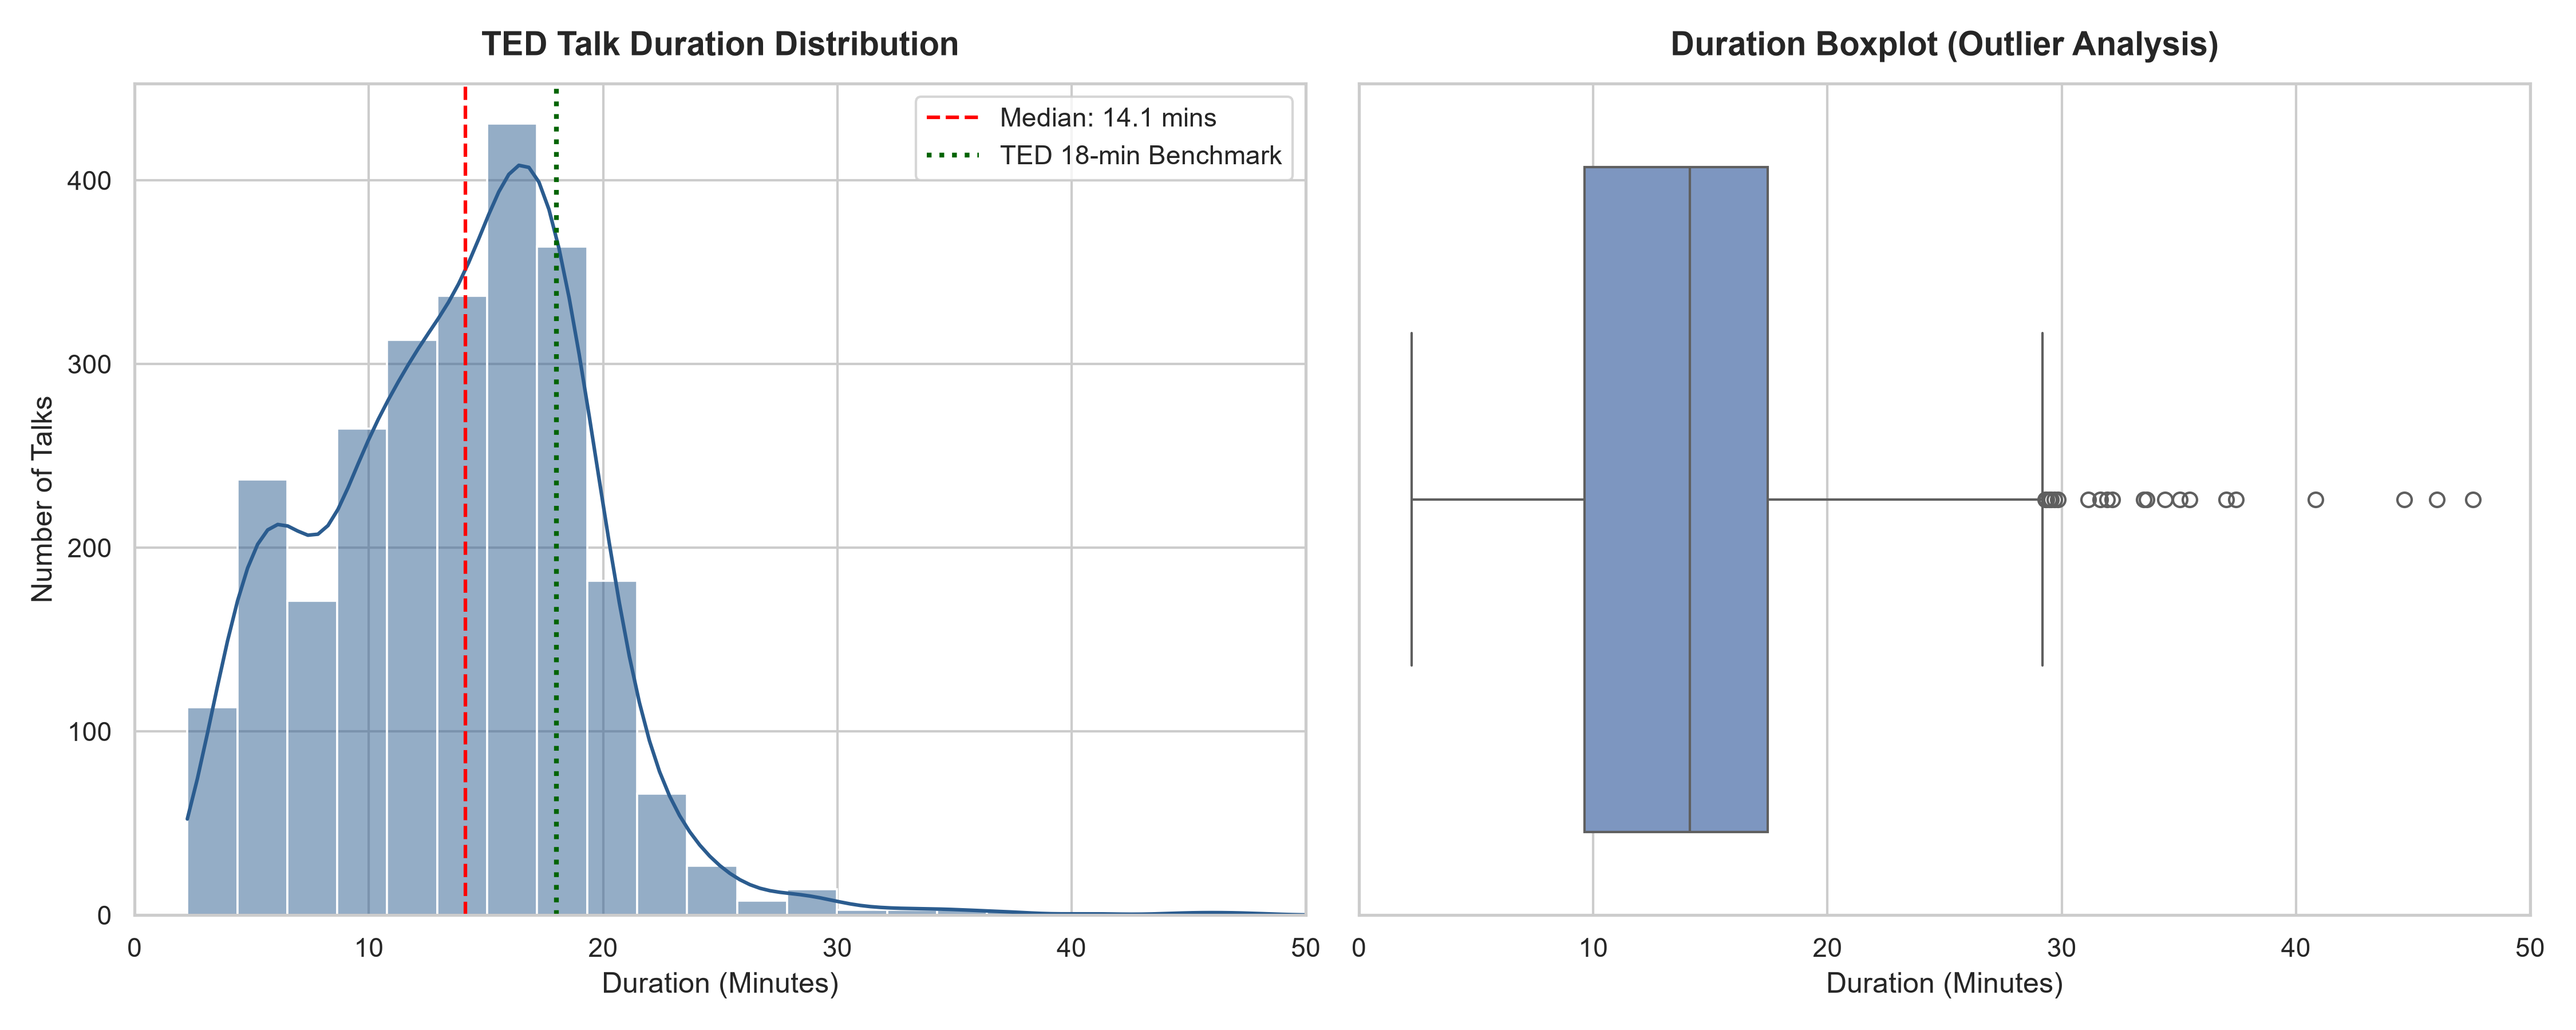

In [13]:
# Visualization 1: Talk Length Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
sns.histplot(df_merged['duration_minutes'], bins=40, kde=True, color='#2b5c8f', ax=ax1)
ax1.axvline(df_merged['duration_minutes'].median(), color='red', linestyle='--', linewidth=1.5,
            label=f"Median: {df_merged['duration_minutes'].median():.1f} mins")
ax1.axvline(18.0, color='darkgreen', linestyle=':', linewidth=2, label="TED 18-min Benchmark")
ax1.set_title("TED Talk Duration Distribution", fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel("Duration (Minutes)", fontsize=12)
ax1.set_ylabel("Number of Talks", fontsize=12)
ax1.legend(fontsize=11)
ax1.set_xlim(0, 50)

sns.boxplot(x=df_merged['duration_minutes'], color='#7293cb', ax=ax2)
ax2.set_title("Duration Boxplot (Outlier Analysis)", fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel("Duration (Minutes)", fontsize=12)
ax2.set_xlim(0, 50)
plt.tight_layout()
plt.savefig("reports/visualizations/talk_length_distribution.png", dpi=300)
plt.show()

[✓] Saved reports/visualizations/top_10_tags.png


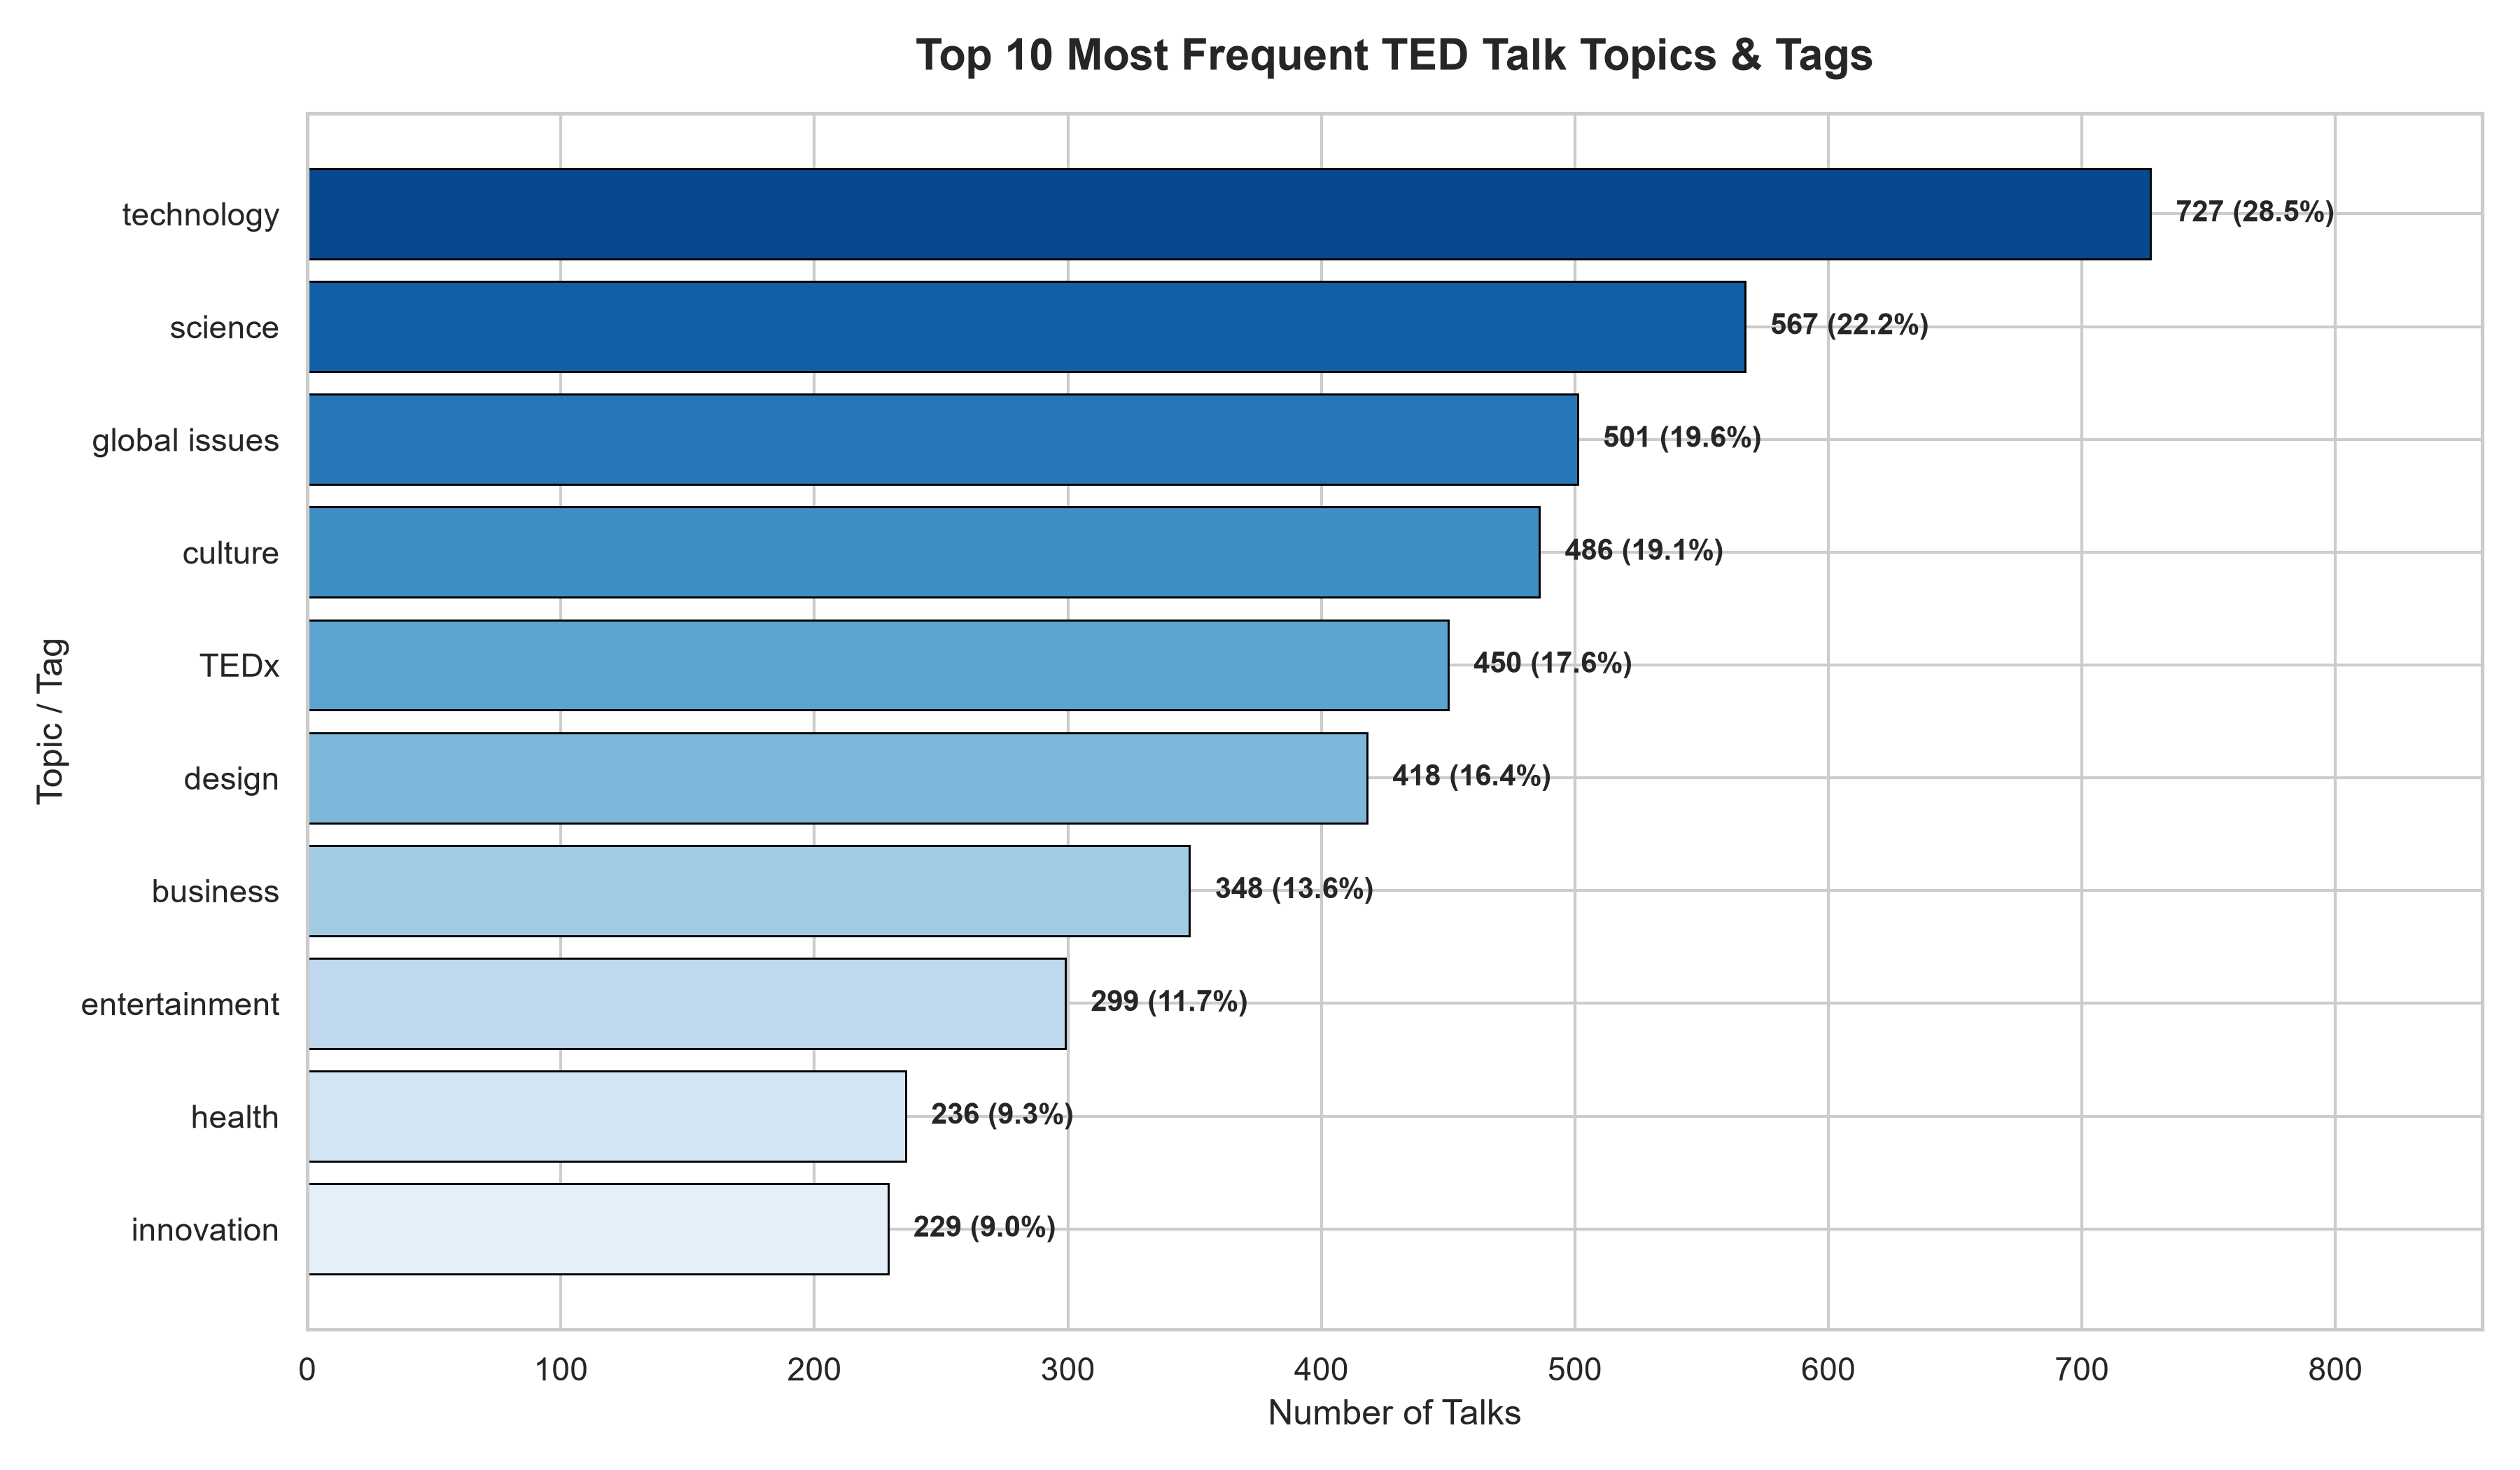

In [14]:
# Visualization 2: Top 10 TED Talk Tags
top_10 = tag_counter.most_common(10)
tags_df = pd.DataFrame(top_10, columns=['Topic / Tag', 'Talk Count'])
tags_df['Percentage'] = (tags_df['Talk Count'] / len(df_merged)) * 100

plt.figure(figsize=(12, 7))
palette = sns.color_palette("Blues_r", len(tags_df))
bars = plt.barh(tags_df['Topic / Tag'][::-1], tags_df['Talk Count'][::-1], color=palette[::-1], edgecolor='black', linewidth=0.7)
for bar in bars:
    w = bar.get_width()
    pct = (w / len(df_merged)) * 100
    plt.text(w + 10, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({pct:.1f}%)", ha='left', va='center', fontsize=10, fontweight='semibold')

plt.title("Top 10 Most Frequent TED Talk Topics & Tags", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Number of Talks", fontsize=12)
plt.ylabel("Topic / Tag", fontsize=12)
plt.xlim(0, max(tags_df['Talk Count']) * 1.18)
plt.tight_layout()
plt.savefig("reports/visualizations/top_10_tags.png", dpi=300)
plt.show()

[✓] Saved reports/visualizations/missing_values_chart.png


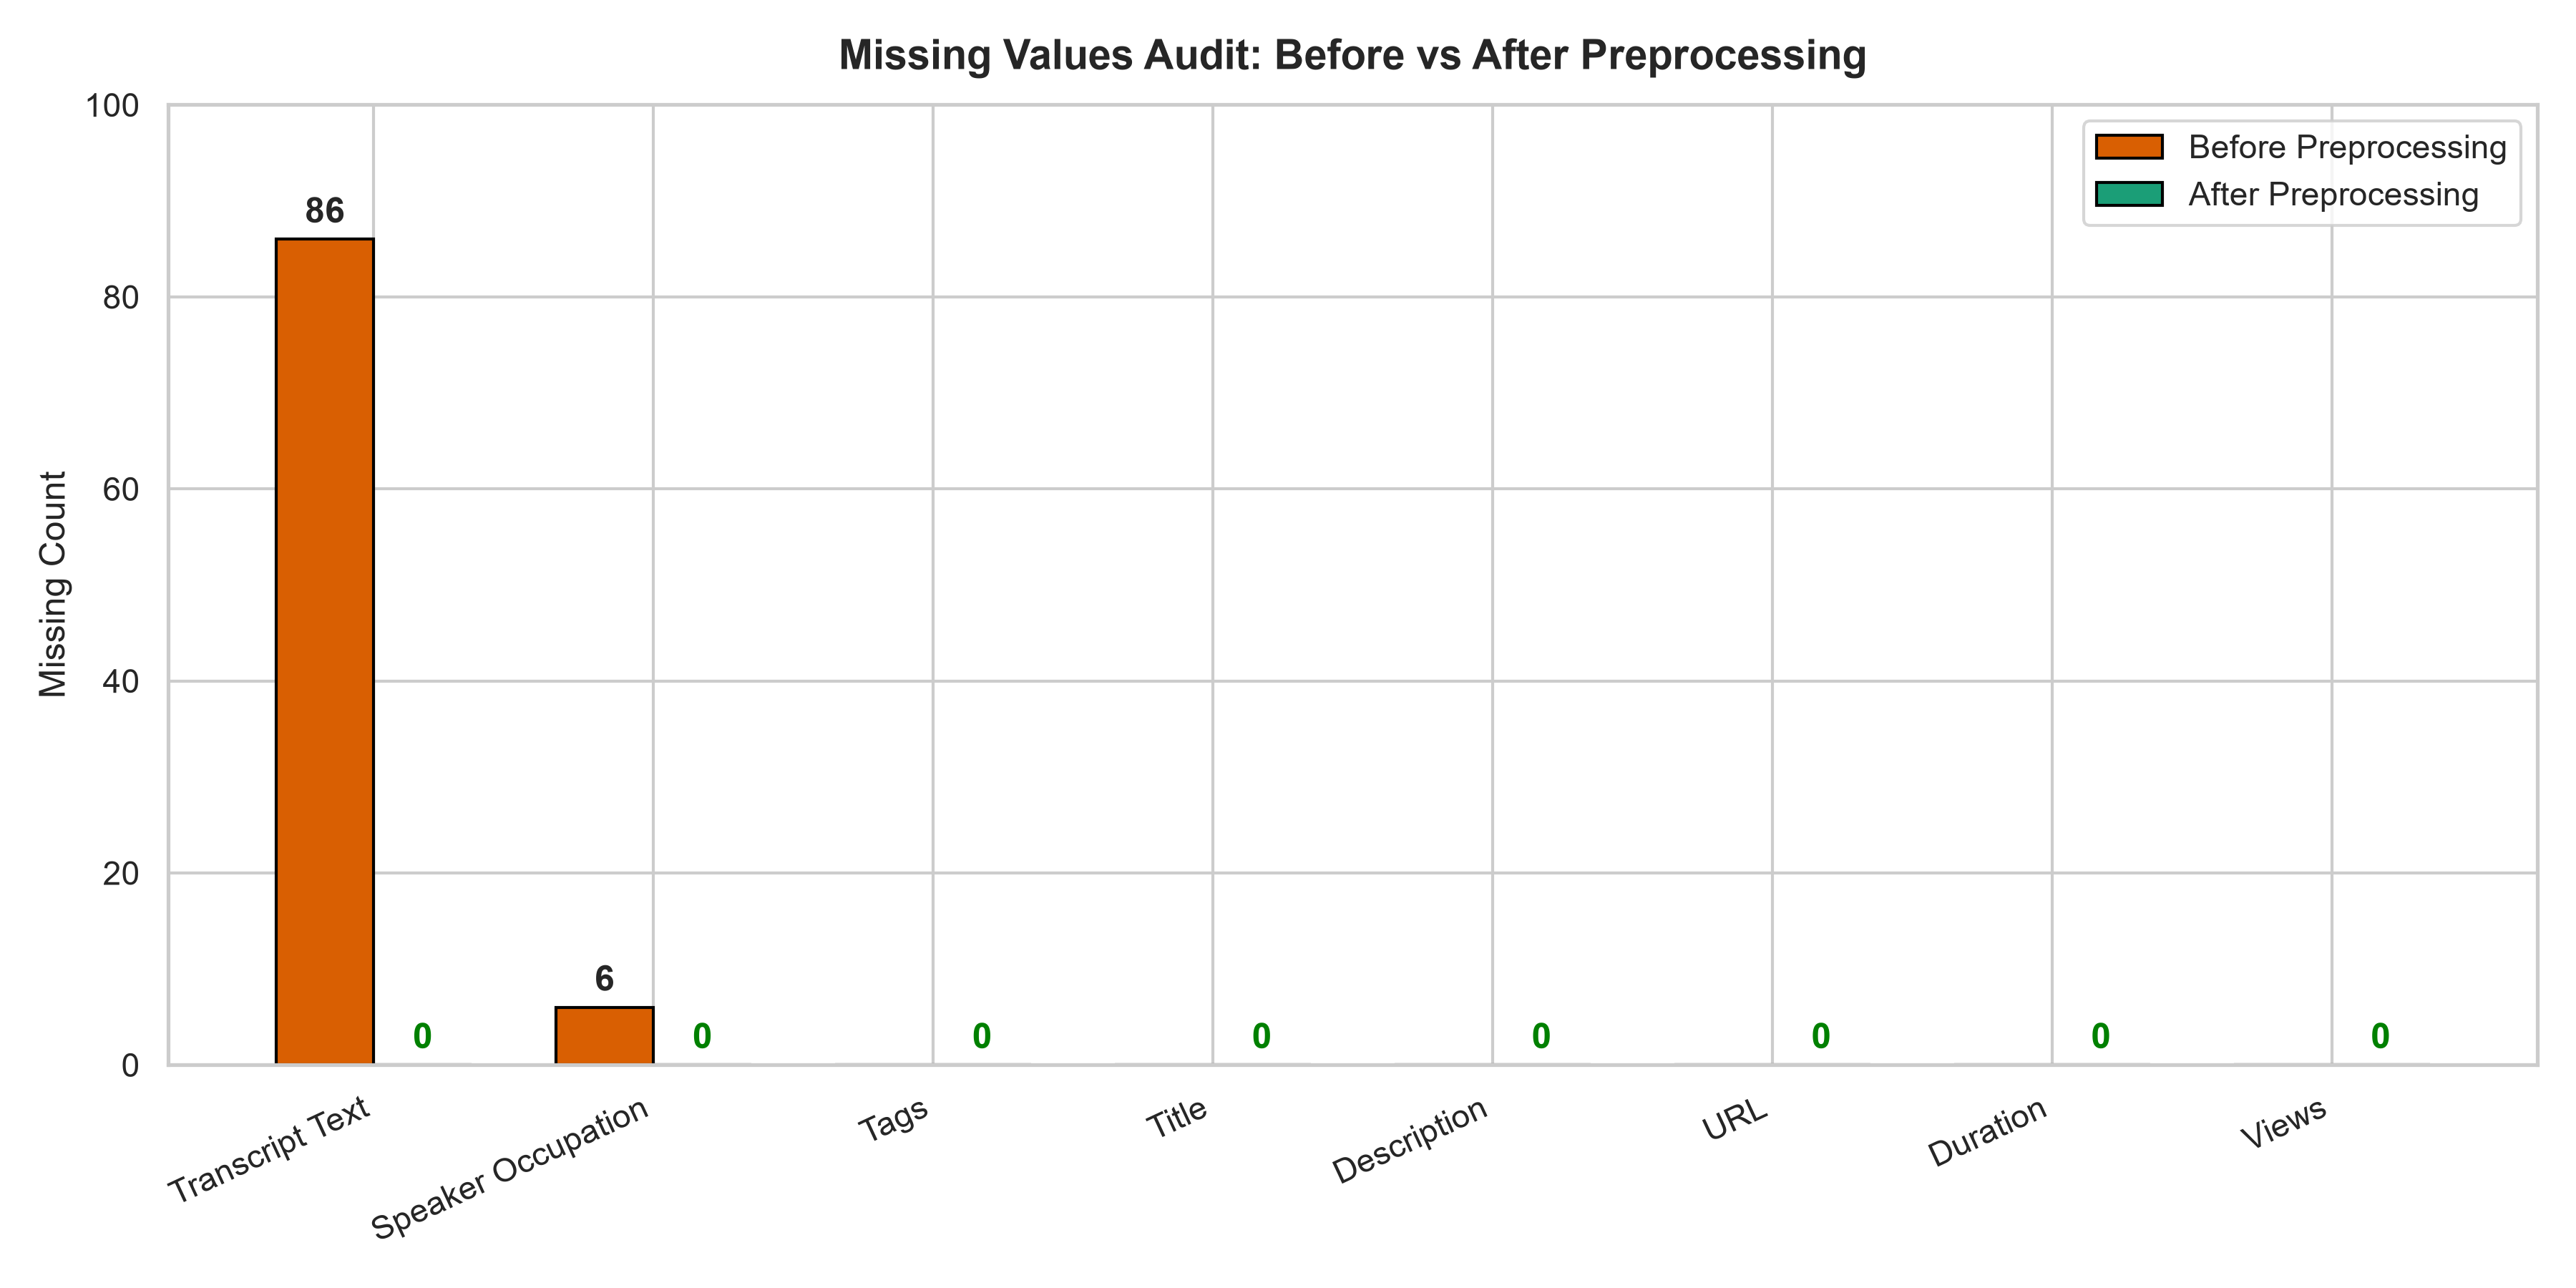

In [15]:
# Visualization 3: Missing Values Chart
missing_audit = pd.DataFrame({
    'Feature': ['Transcript Text', 'Speaker Occupation', 'Tags', 'Title', 'Description', 'URL', 'Duration', 'Views'],
    'Missing (Before)': [86, 6, 0, 0, 0, 0, 0, 0],
    'Missing (After Imputation)': [0, 0, 0, 0, 0, 0, 0, 0]
})

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(missing_audit))
width = 0.35
rects1 = ax.bar(x - width/2, missing_audit['Missing (Before)'], width, label='Before Preprocessing', color='#d95f02', edgecolor='black')
rects2 = ax.bar(x + width/2, missing_audit['Missing (After Imputation)'], width, label='After Preprocessing', color='#1b9e77', edgecolor='black')
ax.set_title("Missing Values Audit: Before vs After Preprocessing", fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel("Missing Count", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(missing_audit['Feature'], rotation=25, ha='right', fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig("reports/visualizations/missing_values_chart.png", dpi=300)
plt.show()

[✓] Saved reports/visualizations/views_distribution.png


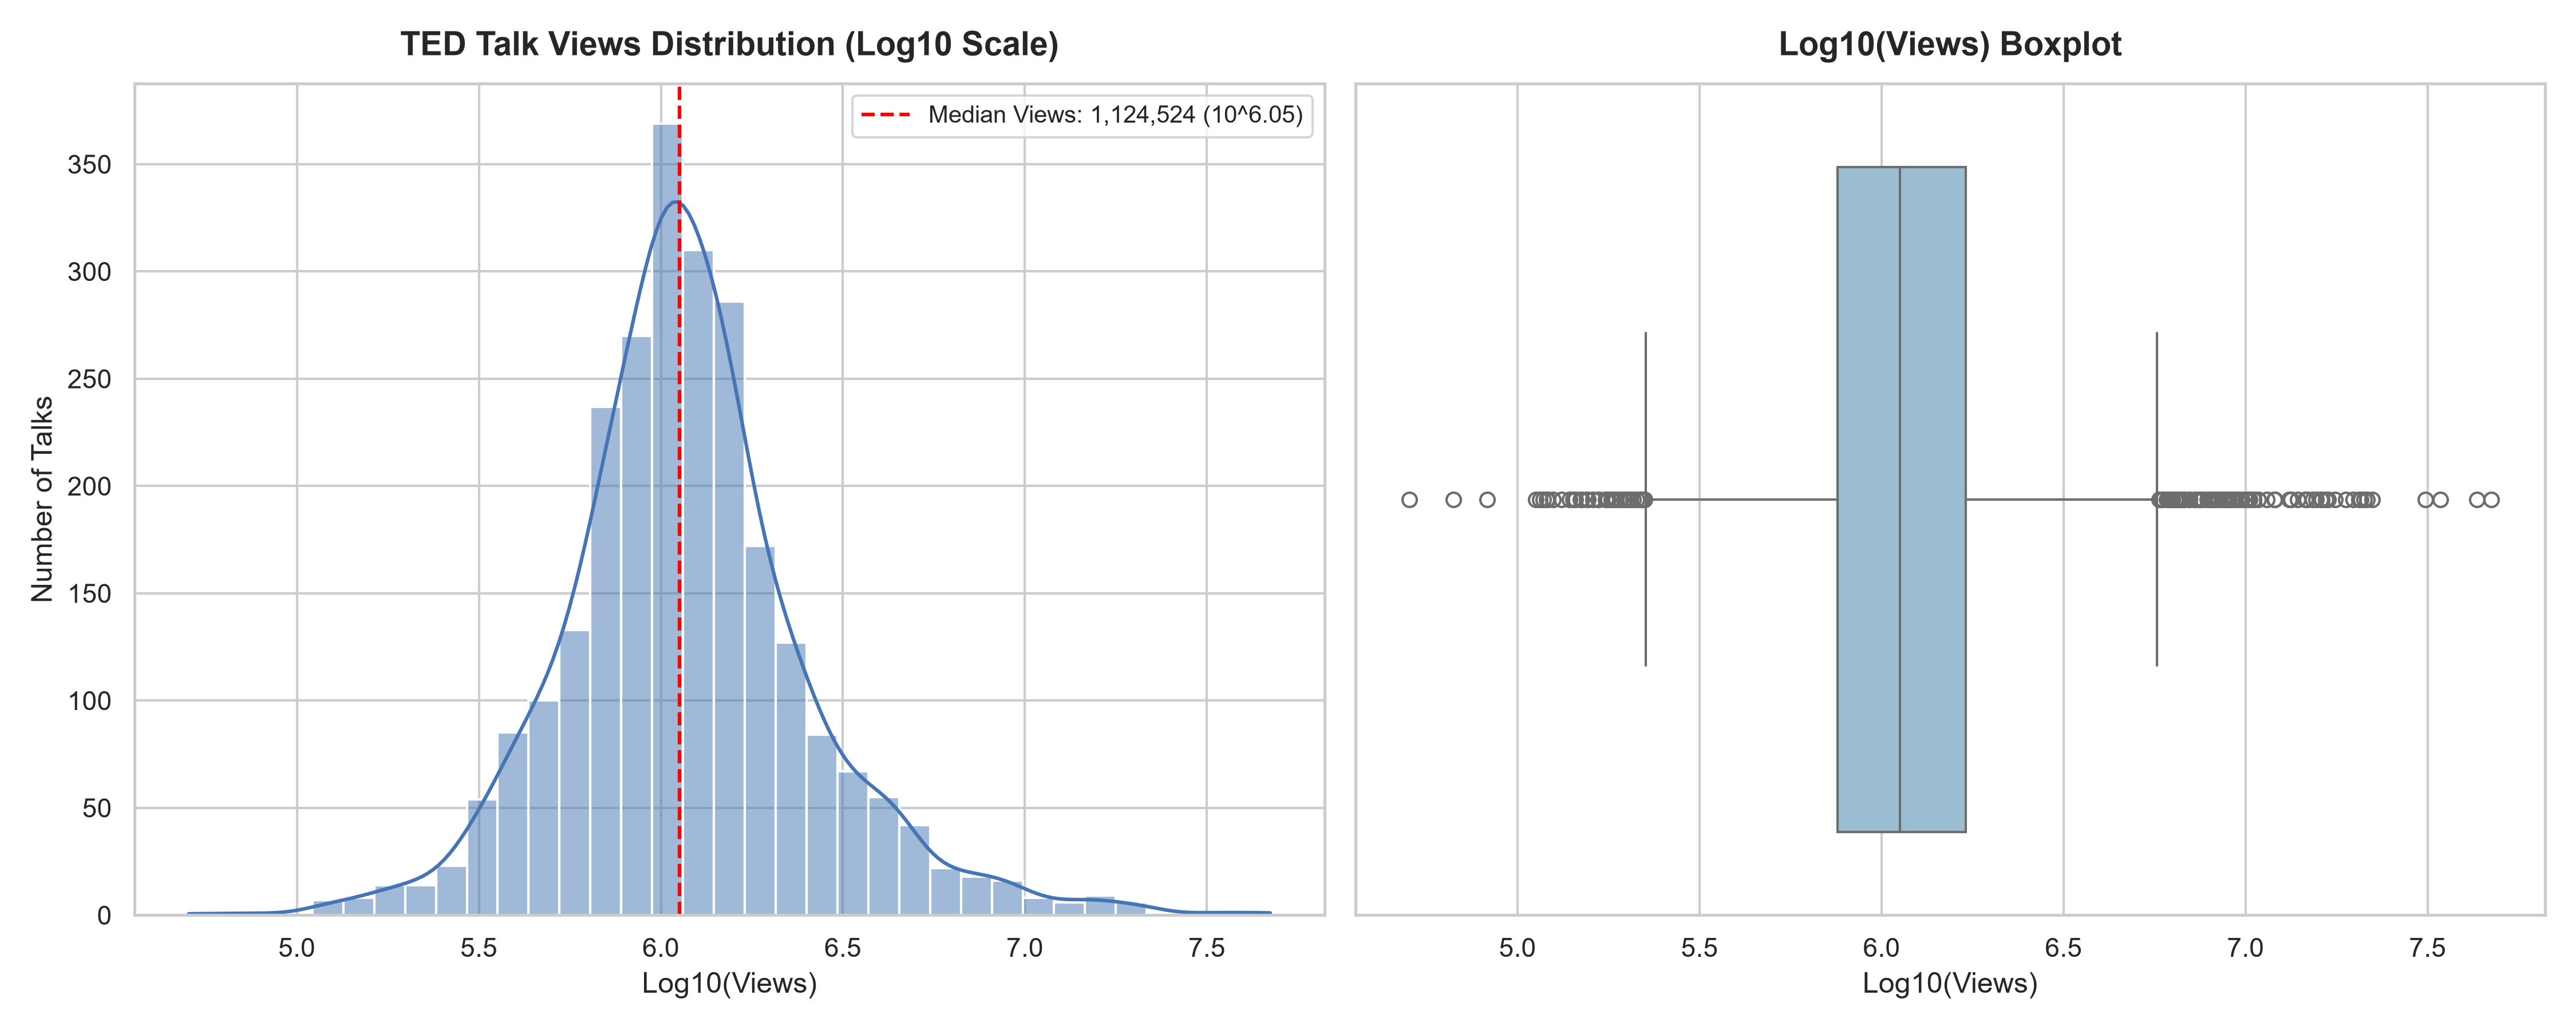

In [16]:
# Visualization 4: Views Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
df_merged['views_log10'] = np.log10(df_merged['views'])
sns.histplot(df_merged['views_log10'], bins=35, kde=True, color='#4575b4', ax=ax1)
ax1.axvline(np.log10(df_merged['views'].median()), color='red', linestyle='--', linewidth=1.5,
            label=f"Median Views: {df_merged['views'].median():,.0f}")
ax1.set_title("TED Talk Views Distribution (Log10 Scale)", fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel("Log10(Views)", fontsize=12)
ax1.set_ylabel("Number of Talks", fontsize=12)
ax1.legend(fontsize=10)

sns.boxplot(x=df_merged['views_log10'], color='#91bfdb', ax=ax2)
ax2.set_title("Log10(Views) Boxplot", fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel("Log10(Views)", fontsize=12)
plt.tight_layout()
plt.savefig("reports/visualizations/views_distribution.png", dpi=300)
plt.show()

In [17]:
# Export cleaned datasets
cleaned_trans_export.to_csv("cleaned_transcripts.csv", index=False, encoding="utf-8")
cleaned_talks_export.to_csv("cleaned_ted_talks.csv", index=False, encoding="utf-8")

print(f"[✓] Saved 'cleaned_transcripts.csv': {len(cleaned_trans_export):,} rows")
print(f"[✓] Saved 'cleaned_ted_talks.csv': {len(cleaned_talks_export):,} rows × {cleaned_talks_export.shape[1]} columns")
print(f"[✓] Saved 'reports/eda_report.txt'")

[✓] Saved 'cleaned_transcripts.csv': 2,464 rows
[✓] Saved 'cleaned_ted_talks.csv': 2,550 rows × 46 columns
[✓] Saved 'reports/eda_report.txt'


## Module 2 Verification Checklist
- [x] Load both datasets using Pandas (`ted_main.csv` and `transcripts.csv`).
- [x] Display first five records of both datasets.
- [x] Check dataset shape (rows and columns).
- [x] Display column names and data types.
- [x] Check missing values in every column.
- [x] Identify duplicate records and resolve transcript duplicate URLs.
- [x] Analyze TED Talk duration and views.
- [x] Analyze the distribution of TED Talk topics and tags.
- [x] Clean transcript text (lowercase, punctuation, extra spaces, stopwords).
- [x] Handle missing transcripts and tags appropriately.
- [x] Encode categorical features (speakers, occupations, top tags).
- [x] Generate EDA visualizations (Talk length, Top 10 tags, Missing values, Views).
- [x] Export `cleaned_ted_talks.csv` and `cleaned_transcripts.csv`.
- [x] Export `reports/eda_report.txt` and save visualizations in `reports/visualizations/`.